# Milestone 2 — Modellreife & Validierung

Aufbauend auf der Baseline (`baseline_model.ipynb`) nutzt dieses Notebook die
bereits vorbereiteten Daten aus `data/processed/cleaned_data.csv`. Die komplette
Datenbereinigung, Spektral-Interpolation, Feature-Engineering und Kodierung
erfolgt zentral in `pipeline/src/data_prep.py`. Dieses Notebook führt nur noch
Train/Test-Split, Cross-Validation, Hyperparameter-Tuning, Strategievergleich
(separat vs. gemeinsames Label vs. hierarchisch) und Fehleranalyse durch.

**Fokus auf die SVM (RBF-Kernel):** Der ausführliche Modellvergleich (RandomForest vs.
HistGradientBoosting vs. MLP, Feature-Engineering-Ablation, zyklisches Month-Encoding,
Split-Verhältnisse) steht in `milestone2_model.ipynb`. In einem früheren Lauf dieses Notebooks
war die SVM dem getunten MLP überlegen (CV Crop 0.932 vs. 0.924, Stage 0.912 vs. 0.900–0.905) und
dabei um ein Vielfaches schneller — das MLP wird deshalb hier nicht mehr gerechnet (Laufzeit vorher ~35 Min.).
Die SVM ist in der Aufgabenstellung explizit genannt und in der Hyperspektral-Literatur das klassische
Referenzverfahren (viele stark korrelierte Bänder, wenige tausend Samples); über `class_weight='balanced'`
kann sie die Klassen-Imbalance (rice, Harvest) direkt berücksichtigen. Ein **ungetuntes
HistGradientBoosting** bleibt als günstige Referenz (Plausibilitätscheck).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
PROCESSED_DATA_PATH = 'data/processed/cleaned_data.csv'
df = pd.read_csv(PROCESSED_DATA_PATH)

# Cleaning, interpolation, feature engineering, and encoding are performed
# by pipeline/src/data_prep.py. This notebook consumes that prepared dataset.
usable_spec_cols = sorted(
    [c for c in df.columns if c.startswith('X')],
    key=lambda c: int(c[1:]),
)
eng_cols = [
    c for c in df.columns
    if c not in usable_spec_cols + ['Crop', 'Stage', 'Month']
]

print(f'Loaded prepared data: {df.shape[0]} rows, {df.shape[1]} columns')
print(f'Usable spectral bands: {len(usable_spec_cols)}')
print(f'Engineered features: {len(eng_cols)}')
print(f'Missing values: {int(df.isna().sum().sum())}')

Loaded prepared data: 5591 rows, 166 columns
Usable spectral bands: 131
Engineered features: 32
Missing values: 0


**Kombinierter Stratifizierungs-Key:** Die Baseline stratifizierte nur auf `Crop` — laut Feedback soll `Stage` ebenfalls berücksichtigt werden. Da `Stage` inhaltlich eine Unterkategorie innerhalb von `Crop` ist (vgl. Aufgabenstellung, z. B. `corn_early`), bilden wir den kombinierten Key `Crop_Stage` und stratifizieren darauf — das erhält gleichzeitig die Verteilung von `Crop` und von `Stage` in Train/Test und in jedem CV-Fold.

In [2]:
df['Crop_Stage'] = df['Crop'] + '|' + df['Stage']
combo_counts = df['Crop_Stage'].value_counts()
print(f"{len(combo_counts)} Crop x Stage combinations, smallest: {combo_counts.idxmin()} with {combo_counts.min()} rows")
pd.crosstab(df['Crop'], df['Stage'])


23 Crop x Stage combinations, smallest: cotton|Harvest with 11 rows


Stage,Critical,Early_Mid,Emerge_VEarly,Harvest,Late,Mature_Senesc
Crop,,,,,,
corn,675,212,152,102,557,399
cotton,158,253,172,11,0,65
rice,0,52,0,0,41,0
soybean,652,465,106,67,233,146
winter_wheat,56,0,608,0,30,379


## Split

Hauptsplit 70/30 (Vergleichbarkeit mit M1), stratifiziert auf `Crop_Stage`. Andere Split-Verhältnisse (80/20, 90/10) wurden in `milestone2_model.ipynb` geprüft und ändern das Ergebnis kaum.

In [3]:
feature_cols_fe = [c for c in df.columns if c not in ['Crop', 'Stage', 'Crop_Stage']]

y_crop = df['Crop']
y_stage = df['Stage']
combo = df['Crop_Stage']

train_idx, test_idx = train_test_split(df.index, test_size=0.3, stratify=combo, random_state=RANDOM_STATE)

X_fe_train, X_fe_test = df.loc[train_idx, feature_cols_fe], df.loc[test_idx, feature_cols_fe]
y_crop_train, y_crop_test = y_crop.loc[train_idx], y_crop.loc[test_idx]
y_stage_train, y_stage_test = y_stage.loc[train_idx], y_stage.loc[test_idx]
combo_train, combo_test = combo.loc[train_idx], combo.loc[test_idx]
targets = {'Crop': y_crop_train, 'Stage': y_stage_train}

print(f'Train: {X_fe_train.shape}  Test: {X_fe_test.shape}')

Train: (3913, 164)  Test: (1678, 164)


## Cross-Validation (Default-Parameter)

5-fache `StratifiedKFold` auf dem `Crop_Stage`-Key des Trainingssplits — dieselbe Fold-Einteilung (`cv_folds`) wird für alle folgenden Schritte verwendet (Tuning, Strategievergleich, hierarchisches Modell). Hier laufen eine SVM (RBF-Kernel, `C=10`, `class_weight='balanced'`; die sklearn-Voreinstellung `C=1` regularisiert für diese Daten zu stark) und als **Referenz** ein `HistGradientBoostingClassifier`, beide mit **Default-Hyperparametern** auf Rohbändern + Feature Engineering. Die Referenz ist ungetunt und kostet nur Sekunden; fällt das MLP nach späteren Änderungen an Pipeline oder Features darunter, ist das ein Warnsignal.

**Overfitting-Check:** `return_train_score=True` liefert zusätzlich die Balanced Accuracy auf den Trainingsfolds; `gap` = Train − CV. Eine hohe Train-Accuracy allein ist bei Bäumen normal — entscheidend ist ein hoher, stabiler CV-Score.

In [4]:
def make_pipe(clf):
    return Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('clf', clf)])

model_factories = {
    'HistGradientBoosting': lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE),  # nur Referenz, ungetunt
    'SVM': lambda: SVC(C=10, class_weight='balanced'),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_folds = list(skf.split(X_fe_train, combo_train))

cv_rows = []
for model_name, factory in model_factories.items():
    for target_name, y_target in targets.items():
        scores = cross_validate(make_pipe(factory()), X_fe_train, y_target, cv=cv_folds,
                                scoring=['balanced_accuracy', 'f1_macro'], return_train_score=True, n_jobs=-1)
        cv_rows.append({
            'model': model_name,
            'target': target_name,
            'cv_balanced_accuracy_mean': scores['test_balanced_accuracy'].mean(),
            'cv_balanced_accuracy_std': scores['test_balanced_accuracy'].std(),
            'cv_f1_macro_mean': scores['test_f1_macro'].mean(),
            'gap': scores['train_balanced_accuracy'].mean() - scores['test_balanced_accuracy'].mean(),
        })
        print(model_name, target_name, f"cv_bacc={cv_rows[-1]['cv_balanced_accuracy_mean']:.3f}", flush=True)

cv_results = pd.DataFrame(cv_rows).sort_values(['target', 'cv_balanced_accuracy_mean'], ascending=[True, False])

def cv_score(model, target):
    return cv_results.query("model == @model and target == @target")['cv_balanced_accuracy_mean'].item()

cv_results.round(3)

HistGradientBoosting Crop cv_bacc=0.903
HistGradientBoosting Stage cv_bacc=0.890
SVM Crop cv_bacc=0.929
SVM Stage cv_bacc=0.907


,model,target,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,cv_f1_macro_mean,gap
2,SVM,Crop,0.929,0.003,0.904,0.025
0,HistGradientBoosting,Crop,0.903,0.023,0.899,0.097
3,SVM,Stage,0.907,0.009,0.891,0.034
1,HistGradientBoosting,Stage,0.890,0.009,0.895,0.110


## Hyperparameter-Tuning (SVM)

Getunt wird die **SVM**, jeweils für Crop und Stage sowie auf dem **gemeinsamen Label** `Crop|Stage` (23 Klassen).

`RandomizedSearchCV` zieht aus dem Suchraster `n_iter` **zufällige Kombinationen** und bewertet jede mit denselben 5 CV-Folds; die beste wird auf dem ganzen Trainingssplit neu gefittet. `n_iter = 20` heißt also: 20 Konfigurationen × 5 Folds = 100 Fits pro Zielgröße — für eine SVM mit zwei kontinuierlichen Hyperparametern ausreichend.

**SVM-Raster:** `C` (Regularisierung) und `gamma` (Reichweite des RBF-Kernels) werden **log-uniform** über mehrere Größenordnungen gezogen, dazu `class_weight` mit und ohne Ausgleich der Klassengrößen. Die Features sind über `make_pipe` standardisiert — für eine SVM zwingend, da der RBF-Kernel auf Abständen beruht.

**Gemeinsames Label:** Die gemeinsame SVM sagt `Crop|Stage` vorher; die Vorhersage wird am `|` zerlegt und Crop und Stage separat mit Balanced Accuracy bewertet. Ausgewählt wird nach dem Mittelwert beider Werte, damit der Score direkt mit den separaten Modellen vergleichbar ist.

Hinweis: `best_score_` ist das Maximum über 20 Kandidaten und daher leicht optimistisch — die ehrliche Schätzung liefert erst der Testsplit unten.

In [5]:
from sklearn.metrics import make_scorer
from scipy.stats import loguniform

# cv_folds kommt aus der CV-Zelle oben (stratifiziert auf Crop|Stage) und wird hier bewusst NICHT neu definiert:
# so nutzen Default-CV, Tuning und hierarchisches Modell exakt dieselben 5 Folds.

N_ITER = 20

param_grids = {
    'SVM': {
        'clf__C': loguniform(1e-1, 1e3),
        'clf__gamma': loguniform(1e-4, 1e-1),
        'clf__class_weight': [None, 'balanced'],
    },
}

def split_joint(pred):
    """'corn|Late' -> (Crop-Array, Stage-Array)"""
    parts = pd.Series(np.asarray(pred)).str.split('|', expand=True)
    return parts[0].to_numpy(), parts[1].to_numpy()

def joint_crop_bacc(y_true, y_pred):
    return balanced_accuracy_score(split_joint(y_true)[0], split_joint(y_pred)[0])

def joint_stage_bacc(y_true, y_pred):
    return balanced_accuracy_score(split_joint(y_true)[1], split_joint(y_pred)[1])

joint_scoring = {
    'mean': make_scorer(lambda yt, yp: (joint_crop_bacc(yt, yp) + joint_stage_bacc(yt, yp)) / 2),
    'crop': make_scorer(joint_crop_bacc),
    'stage': make_scorer(joint_stage_bacc)
}

tuned = {}
tuning_rows = []

for model_name in ['SVM']:
    for target_name in ['Crop', 'Stage', 'Joint']:
        y_fit = combo_train if target_name == 'Joint' else targets[target_name]
        search = RandomizedSearchCV(
            estimator=make_pipe(model_factories[model_name]()),
            param_distributions=param_grids[model_name],
            n_iter=N_ITER,
            cv=cv_folds,
            scoring=joint_scoring if target_name == 'Joint' else 'balanced_accuracy',
            refit='mean' if target_name == 'Joint' else True,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        search.fit(X_fe_train, y_fit)

        if target_name == 'Joint':
            r, i = search.cv_results_, search.best_index_
            cv = {'Crop': r['mean_test_crop'][i], 'Stage': r['mean_test_stage'][i]}
        else:
            cv = {target_name: search.best_score_}

        tuned[(model_name, target_name)] = {'estimator': search.best_estimator_, 'params': search.best_params_, 'cv': cv}

        for t, s in cv.items():
            tuning_rows.append({
                'model': model_name,
                'strategie': 'gemeinsam' if target_name == 'Joint' else 'separat',
                'target': t,
                'cv_bacc_default': cv_score(model_name, t) if target_name != 'Joint' else np.nan,
                'cv_bacc_tuned': s,
                'key': (model_name, target_name),  # Schlüssel in `tuned`
            })

        print(model_name, target_name, search.best_params_, {k: round(v, 3) for k, v in cv.items()}, flush=True)

SVM Crop {'clf__C': 138.26232179369853, 'clf__class_weight': None, 'clf__gamma': 0.0014040609919104426} {'Crop': 0.932}
SVM Stage {'clf__C': 785.2755494724249, 'clf__class_weight': None, 'clf__gamma': 0.002334586407601623} {'Stage': 0.904}
SVM Joint {'clf__C': 785.2755494724249, 'clf__class_weight': None, 'clf__gamma': 0.002334586407601623} {'Crop': 0.922, 'Stage': 0.912}


### Strategievergleich: separate Modelle vs. gemeinsames Label

Getunte SVM separat vs. gemeinsam, CV-Score pro Zielgröße (beim gemeinsamen Modell nach dem Zerlegen der Vorhersage). `cv_bacc_default` ist die ungetunte SVM aus der CV oben; beim gemeinsamen Modell gibt es keinen Default-Lauf (`NaN`).

In [6]:
tuning_results = pd.DataFrame(tuning_rows).sort_values(['target', 'cv_bacc_tuned'], ascending=[True, False])
tuning_results.drop(columns='key').round(3)

,model,strategie,target,cv_bacc_default,cv_bacc_tuned
0,SVM,separat,Crop,0.929,0.932
2,SVM,gemeinsam,Crop,NaN,0.922
3,SVM,gemeinsam,Stage,NaN,0.912
1,SVM,separat,Stage,0.907,0.904


### Hierarchische SVM: erst Crop, dann Stage innerhalb der Kultur

Dritte Strategie neben *separat* und *gemeinsames Label*, wie in der Aufgabenstellung beschrieben (*Local Classifier per Parent Node*):

1. **Stufe 1:** Eine SVM sagt die **Crop** vorher (= die getunte separate Crop-SVM).
2. **Stufe 2:** Für **jede Kultur eine eigene Stage-SVM**, trainiert nur auf den Zeilen dieser Kultur. Sie kann nur Stadien vorhersagen, die es für die Kultur gibt (siehe Kreuztabelle oben — z. B. `rice` nur `Early_Mid`/`Late`, `winter_wheat` nie `Early_Mid`), und lernt kulturspezifische Spektren (ein reifender Weizen sieht anders aus als reifender Mais).
3. **Vorhersage:** Crop aus Stufe 1, dann Stage aus der SVM der **vorhergesagten** Kultur.

**Vor- und Nachteile:** Die Hierarchie bildet die Struktur der Aufgabe direkt ab und ist interpretierbar. Dafür **pflanzen sich Crop-Fehler fort** — wird die Kultur falsch erkannt, entscheidet das falsche Stage-Modell — und die Stage-Modelle sehen jeweils nur einen Teil der Daten (`rice`: ~65 Trainingszeilen).

**Leakage:** Stufe 2 wird auf den echten Crop-Gruppen trainiert; das Crop-Label dient dabei nur zur Auswahl der Trainingszeilen, nie als Feature. In der Vorhersage wird ausschließlich die vorhergesagte Crop verwendet. Die ganze Hierarchie steckt in einem Estimator (`HierarchicalClassifier`, gefittet auf `Crop|Stage`), läuft also in der CV in jedem Fold nur auf dessen Trainingsteil.

**Tuning:** Die Crop-Stufe ist fest (getunte Crop-SVM); die Hyperparameter der Stage-Stufe werden mit `RandomizedSearchCV` auf denselben Folds gesucht, bewertet nach der Stage-Balanced-Accuracy der ganzen Hierarchie (inkl. fortgepflanzter Crop-Fehler). Alle Kulturen teilen sich dieselben Stage-Hyperparameter — ein eigenes Tuning pro Kultur wäre bei den kleinen Gruppen zu instabil.

Ersetzt die Classifier Chain aus der vorherigen Version: Beide sagen erst das eine Ziel und dann das andere vorher; die Hierarchie ist die in der Aufgabenstellung genannte Variante, schneller und einfacher zu erklären.

In [7]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone


class HierarchicalClassifier(BaseEstimator, ClassifierMixin):
    """Erst Crop, dann Stage mit einem eigenen Modell pro (vorhergesagter) Crop.

    Wird auf dem gemeinsamen Label `Crop|Stage` gefittet -- nur damit beide Zielgrößen durch die
    sklearn-API (cross_validate, RandomizedSearchCV, Scorer) gereicht werden -- und sagt `Crop|Stage` vorher.
    """

    def __init__(self, crop_model, stage_model):
        self.crop_model = crop_model
        self.stage_model = stage_model

    def fit(self, X, y):
        crop, stage = split_joint(y)
        self.crop_ = clone(self.crop_model).fit(X, crop)
        self.stage_ = {}
        for c in np.unique(crop):
            rows = crop == c
            stages_c = np.unique(stage[rows])
            # Kultur mit nur einem Stadium im Training: konstante Vorhersage statt Modell
            self.stage_[c] = stages_c[0] if len(stages_c) == 1 else clone(self.stage_model).fit(X[rows], stage[rows])
        self.classes_ = np.unique(np.asarray(y))
        return self

    def predict(self, X):
        crop = self.crop_.predict(X)
        stage = np.empty(len(X), dtype=object)
        for c in np.unique(crop):
            rows = crop == c
            model = self.stage_[c]
            stage[rows] = model if isinstance(model, str) else model.predict(X[rows])
        return pd.Series(crop).astype(str).str.cat(pd.Series(stage).astype(str), sep='|').to_numpy()


hier_search = RandomizedSearchCV(
    estimator=HierarchicalClassifier(clone(tuned[('SVM', 'Crop')]['estimator']), make_pipe(model_factories['SVM']())),
    param_distributions={f'stage_model__{k}': v for k, v in param_grids['SVM'].items()},
    n_iter=N_ITER,
    cv=cv_folds,
    scoring={'crop': joint_scoring['crop'], 'stage': joint_scoring['stage']},
    refit='stage',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
hier_search.fit(X_fe_train, combo_train)
r, i = hier_search.cv_results_, hier_search.best_index_
key = ('SVM → SVM', 'Hier')
tuned[key] = {'estimator': hier_search.best_estimator_, 'params': hier_search.best_params_,
              'cv': {'Crop': r['mean_test_crop'][i], 'Stage': r['mean_test_stage'][i]}, 'strategie': 'hierarchisch'}
hier_rows = [{'model': key[0], 'strategie': 'hierarchisch', 'target': t, 'cv_bacc_default': np.nan,
              'cv_bacc_tuned': s, 'key': key} for t, s in tuned[key]['cv'].items()]
print('Hierarchisch', hier_search.best_params_, {t: round(s, 3) for t, s in tuned[key]['cv'].items()},
      f"Stage pro Fold {np.array([r[f'split{k}_test_stage'][i] for k in range(5)]).round(3)}")

tuning_results = pd.DataFrame(tuning_rows + hier_rows).sort_values(['target', 'cv_bacc_tuned'], ascending=[True, False])
tuning_results.drop(columns='key').round(3)

Hierarchisch {'stage_model__clf__C': 44.677528179739035, 'stage_model__clf__class_weight': 'balanced', 'stage_model__clf__gamma': 0.0018856783874794986} {'Crop': 0.932, 'Stage': 0.906} Stage pro Fold [0.916 0.906 0.914 0.886 0.91 ]


,model,strategie,target,cv_bacc_default,cv_bacc_tuned
0,SVM,separat,Crop,0.929,0.932
4,SVM → SVM,hierarchisch,Crop,NaN,0.932
2,SVM,gemeinsam,Crop,NaN,0.922
3,SVM,gemeinsam,Stage,NaN,0.912
5,SVM → SVM,hierarchisch,Stage,NaN,0.906
1,SVM,separat,Stage,0.907,0.904


**Modellauswahl:** Pro Zielgröße gewinnt die Strategie (separat, gemeinsam, hierarchisch) mit dem höchsten CV-Score in `cv_bacc_tuned`. Der Testsplit wird für die Auswahl **nicht** verwendet.

## Finaler Fit & Fehleranalyse

Die ausgewählten Modelle (bereits auf dem vollen Trainingssplit refittet durch `RandomizedSearchCV`) werden einmalig auf dem Test-Split (30 %, nie für CV/Tuning/Auswahl verwendet) ausgewertet — inkl. Confusion Matrix pro Klasse für die Fehleranalyse. Bei einem gemeinsamen oder hierarchischen Modell wird die `Crop|Stage`-Vorhersage zerlegt.

Crop: SVM (separat)  CV balanced_accuracy=0.932
Stage: SVM (gemeinsam)  CV balanced_accuracy=0.912
Crop - Modell: SVM (separat) - Balanced Accuracy: 0.922, Macro F1: 0.923
              precision    recall  f1-score   support

        corn       0.95      0.94      0.94       630
      cotton       0.89      0.92      0.90       197
        rice       0.96      0.93      0.95        28
     soybean       0.92      0.93      0.92       501
winter_wheat       0.90      0.90      0.90       322

    accuracy                           0.92      1678
   macro avg       0.92      0.92      0.92      1678
weighted avg       0.92      0.92      0.92      1678



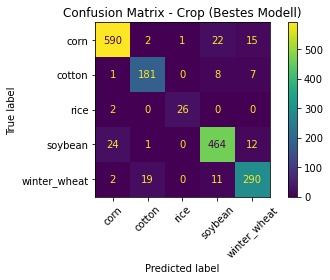

Stage - Modell: SVM (gemeinsam) - Balanced Accuracy: 0.908, Macro F1: 0.909
               precision    recall  f1-score   support

     Critical       0.93      0.95      0.94       462
    Early_Mid       0.88      0.90      0.89       295
Emerge_VEarly       0.91      0.89      0.90       312
      Harvest       0.89      0.89      0.89        54
         Late       0.96      0.97      0.97       258
Mature_Senesc       0.87      0.86      0.86       297

     accuracy                           0.91      1678
    macro avg       0.91      0.91      0.91      1678
 weighted avg       0.91      0.91      0.91      1678



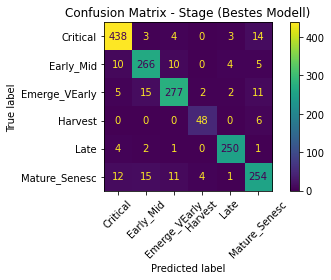

In [8]:
# 1. Finde automatisch das beste Modell für 'Crop' und 'Stage' basierend auf dem höchsten CV-Score
best_per_target = {}

for target in ['Crop', 'Stage']:
    # Filtere die Ergebnisse nach dem aktuellen Target und ignoriere NaN-Werte (ungetunte Referenz)
    target_results = tuning_results[(tuning_results['target'] == target) & (tuning_results['cv_bacc_tuned'].notna())]

    # Finde die Zeile mit dem höchsten CV-Score
    best_row = target_results.loc[target_results['cv_bacc_tuned'].idxmax()]
    key = best_row['key']  # Schlüssel in `tuned`, z. B. ('SVM', 'Joint') oder ('SVM → SVM', 'Hier')

    best_per_target[target] = {
        'best_estimator': tuned[key]['estimator'],
        # gemeinsame und hierarchische Modelle sagen 'Crop|Stage' vorher -> Vorhersage muss zerlegt werden
        'joint': key[1] != target,
        'label': f"{best_row['model']} ({best_row['strategie']})",
        'cv_best_score': best_row['cv_bacc_tuned'],
    }
    print(f"{target}: {best_per_target[target]['label']}  CV balanced_accuracy={best_row['cv_bacc_tuned']:.3f}")

# 2. Hilfsfunktion für die Vorhersage
def predict_target(estimator, joint, target_name, X):
    pred = estimator.predict(X)
    return split_joint(pred)[0 if target_name == 'Crop' else 1] if joint else pred

# 3. Evaluierung auf den Testdaten
for target_name, y_test_sel in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
    info = best_per_target[target_name]
    pred = predict_target(info['best_estimator'], info['joint'], target_name, X_fe_test)

    bacc = balanced_accuracy_score(y_test_sel, pred)
    f1 = f1_score(y_test_sel, pred, average='macro')
    info['test_bacc'] = bacc
    info['test_f1'] = f1

    print(f"{target_name} - Modell: {info['label']} - Balanced Accuracy: {bacc:.3f}, Macro F1: {f1:.3f}")
    print(classification_report(y_test_sel, pred))

    ConfusionMatrixDisplay.from_predictions(y_test_sel, pred, xticks_rotation=45)
    plt.title(f'Confusion Matrix - {target_name} (Bestes Modell)')
    plt.tight_layout()
    plt.show()

**Alle Kandidaten auf dem Test-Split** — nur zur Einordnung (die Auswahl oben erfolgte allein per CV). Dazu das ungetunte HGB als Referenz, einmal auf dem ganzen Trainingssplit gefittet.

In [9]:
test_rows = []
for (model_name, strat), info in tuned.items():
    for target_name, y_true in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
        if target_name not in info['cv']:
            continue
        pred = predict_target(info['estimator'], strat != target_name, target_name, X_fe_test)
        strategie = info.get('strategie', 'gemeinsam' if strat == 'Joint' else 'separat')
        test_rows.append({'target': target_name, 'model': model_name, 'strategie': strategie,
                          'cv_bacc': info['cv'][target_name], 'test_bacc': balanced_accuracy_score(y_true, pred),
                          'test_f1_macro': f1_score(y_true, pred, average='macro')})
# Referenz: ungetuntes HGB (Default-Parameter), dauert nur Sekunden
for target_name, y_true in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
    pred = make_pipe(model_factories['HistGradientBoosting']()).fit(X_fe_train, targets[target_name]).predict(X_fe_test)
    test_rows.append({'target': target_name, 'model': 'HistGradientBoosting', 'strategie': 'Referenz (Default, ungetunt)',
                      'cv_bacc': cv_score('HistGradientBoosting', target_name), 'test_bacc': balanced_accuracy_score(y_true, pred),
                      'test_f1_macro': f1_score(y_true, pred, average='macro')})
test_results = pd.DataFrame(test_rows).sort_values(['target', 'cv_bacc'], ascending=[True, False])
test_results.round(3)

,target,model,strategie,cv_bacc,test_bacc,test_f1_macro
0,Crop,SVM,separat,0.932,0.922,0.923
4,Crop,SVM → SVM,hierarchisch,0.932,0.922,0.923
2,Crop,SVM,gemeinsam,0.922,0.915,0.919
6,Crop,HistGradientBoosting,"Referenz (Default, ungetunt)",0.903,0.892,0.887
3,Stage,SVM,gemeinsam,0.912,0.908,0.909
5,Stage,SVM → SVM,hierarchisch,0.906,0.903,0.892
1,Stage,SVM,separat,0.904,0.899,0.907
7,Stage,HistGradientBoosting,"Referenz (Default, ungetunt)",0.890,0.887,0.890


## Zusammenfassung & Vergleich ggü. Baseline

In [10]:
rows = []
for target_name, m1_bacc, m1_f1, m2_bacc, m2_f1 in [('Crop', 0.778, 0.810, 0.877, 0.882), ('Stage', 0.769, 0.788, 0.874, 0.877)]:
    info = best_per_target[target_name]
    rows += [
        {'Zielgroesse': target_name, 'Modell': 'M1 Baseline (RandomForest)', 'Balanced Accuracy': m1_bacc, 'Macro F1': m1_f1},
        {'Zielgroesse': target_name, 'Modell': 'M2 ohne FE (HistGradientBoosting, Rohbaender)', 'Balanced Accuracy': m2_bacc, 'Macro F1': m2_f1},
        {'Zielgroesse': target_name, 'Modell': f"M2 final: {info['label']}",
         'Balanced Accuracy': info['test_bacc'], 'Macro F1': info['test_f1']},
    ]
summary = pd.DataFrame(rows)
summary.round(3)

,Zielgroesse,Modell,Balanced Accuracy,Macro F1
0,Crop,M1 Baseline (RandomForest),0.778,0.810
1,Crop,"M2 ohne FE (HistGradientBoosting, Rohbaender)",0.877,0.882
2,Crop,M2 final: SVM (separat),0.922,0.923
3,Stage,M1 Baseline (RandomForest),0.769,0.788
4,Stage,"M2 ohne FE (HistGradientBoosting, Rohbaender)",0.874,0.877
5,Stage,M2 final: SVM (gemeinsam),0.908,0.909


**Beobachtungen**

Der Vergleich RandomForest vs. HGB vs. MLP, die Feature-Engineering-Ablation, zyklisches Month-Encoding und Split-Verhältnisse stehen in `milestone2_model.ipynb` und werden hier nicht mehr gerechnet. Laufzeit dieses Notebooks: ca. 7 Min. (mit MLP vorher ~35 Min.).

- **SVM vs. Referenz:** Schon ungetunt (`C=10`) liegt die SVM in der CV klar vor dem ungetunten HGB (Crop 0.929 vs. 0.903, Stage 0.907 vs. 0.890), mit kleinerer Fold-Streuung (Std 0.003–0.009) und deutlich kleinerer Train-CV-Lücke (gap 0.03 vs. 0.10–0.11).
- **Tuning-Effekt:** gering — Crop 0.929 → 0.932, Stage 0.907 → 0.904 (separat). Bevorzugt werden große `C` (≈ 140–790) mit kleinem `gamma` (≈ 0.001–0.002), also ein glatter Kernel mit wenig Regularisierung; `class_weight='balanced'` bringt bei den separaten Modellen nichts.
- **Strategievergleich (CV):**
  - Crop: separat **0.932** = hierarchisch 0.932 (identisch, da die erste Stufe die separate Crop-SVM ist) > gemeinsam 0.922.
  - Stage: gemeinsam **0.912** > hierarchisch 0.906 > separat 0.904. Die Unterschiede liegen im Bereich der Fold-Streuung (hierarchisch pro Fold 0.886–0.916).
- **Hierarchische SVM:** Die kulturspezifischen Stage-Modelle helfen gegenüber einem globalen Stage-Modell nur minimal (+0.002 CV). Ein Teil des Vorteils geht durch fortgepflanzte Crop-Fehler (~8 % der Zeilen) und kleine Trainingsgruppen (`rice` ~65 Zeilen) wieder verloren. Das gemeinsame Label nutzt die Crop-Stage-Struktur ebenfalls (es kann nur existierende Kombinationen vorhersagen), entscheidet aber Crop und Stage in einem Schritt — ohne Fehlerfortpflanzung — und gewinnt daher bei Stage. Für die Stage-Stufe wählt das Tuning `class_weight='balanced'`, da die Gruppen innerhalb einer Kultur stark unausgeglichen sind (z. B. `cotton|Harvest` mit 11 Zeilen).
- **Overfitting-Check (gap = Train − CV, Default-Parameter):** SVM 0.025 (Crop) / 0.034 (Stage), HGB 0.097 / 0.110.
- **Finale Testset-Ergebnisse (Auswahl per CV, Testsplit nie für CV/Tuning/Auswahl verwendet):** Crop **0.922** (SVM separat; Macro F1 0.923), Stage **0.908** (SVM gemeinsames Label; Macro F1 0.909). Hierarchisch auf dem Testsplit: Crop 0.922, Stage 0.903 — bestätigt die CV-Reihenfolge.
- **Fehleranalyse:** Crop — `rice` am stärksten (F1 0.95, nur 28 Testfälle), `corn` 0.94, `cotton`/`winter_wheat` am schwächsten (F1 0.90). Stage — `Late` am stärksten (F1 0.97), `Mature_Senesc` am schwächsten (F1 0.86, Verwechslung mit benachbarten Reifephasen), `Harvest` trotz nur 54 Testfällen bei F1 0.89.
- **Einschränkungen:** `best_score_` ist als Maximum über 20 Kandidaten leicht optimistisch; die Stage-Hyperparameter der Hierarchie gelten für alle Kulturen gemeinsam. Die Werte „M2 ohne FE“ in der Zusammenfassung sind fest eingetragen und stammen aus einem früheren Lauf.
